# Modularity on the Karate Club Graph
**DSC212: Graph Theory Module — Research Assignment**

This notebook implements **recursive spectral modularity partitioning** from scratch (NumPy + NetworkX only) on Zachary's Karate Club network, following the assignment handout and Newman (2006).

**Pipeline**
1. Load the graph and build the modularity matrix $B = A - \frac{k k^\top}{2m}$.
2. Bisect a community $C$ with the sign of the leading eigenvector of $B^{(C)}$ (Newman's generalised block $B^{(C)}$, with the diagonal correction); stop when $\lambda_1^{(C)} \le 0$ or the split would not increase $Q$.
3. Visualise the graph after every split (fixed spring layout, one colour per community, node IDs as labels).
4. After every split compute degree, betweenness and closeness centrality and the clustering coefficient with NetworkX.
5. Plot how every metric evolves per node across iterations and discuss.

**Conventions used (stated explicitly so the results are reproducible)**
- *Iteration 0* is the whole graph as one community; *iteration t* is the state right after the $t$-th successful split. Communities are processed first-in-first-out.
- Node metrics after each split are computed **within each node's current community** (on the induced subgraph `G.subgraph(C)`), because metrics on the full graph would not change between iterations. The full-graph values are exactly the iteration-0 values.
- All graph objects are treated as **unweighted** (`weight=None`), matching the handout's $A_{ij}\in\{0,1\}$.

## 1. Setup and data

In [1]:
import os
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True, linewidth=120)
os.makedirs("assets", exist_ok=True)   # figures are also saved here for the repository

TOL = 1e-10     # numerical tolerance used for the test  lambda_1 <= 0

In [2]:
G = nx.karate_club_graph()
nodes = sorted(G.nodes())                       # 0, 1, ..., 33
n, m = G.number_of_nodes(), G.number_of_edges()

# Adjacency matrix. weight=None forces a 0/1 matrix (some NetworkX versions attach edge weights).
A = nx.to_numpy_array(G, nodelist=nodes, weight=None)
k = A.sum(axis=1)                               # degree vector

assert n == 34 and m == 78
assert set(np.unique(A)) <= {0.0, 1.0} and np.allclose(A, A.T)
assert np.isclose(k.sum(), 2 * m)
print(f"n = {n} nodes, m = {m} edges, sum of degrees = {int(k.sum())} (= 2m)")

# Ground truth: the real split of the club (stored by NetworkX as the 'club' node attribute)
truth = np.array([1 if G.nodes[i]["club"] == "Mr. Hi" else -1 for i in nodes])
print("Mr. Hi's faction:", [i for i in nodes if truth[i] == 1])
print("Officer's faction:", [i for i in nodes if truth[i] == -1])

n = 34 nodes, m = 78 edges, sum of degrees = 156 (= 2m)
Mr. Hi's faction: [0, 1, 2, 3, 4, 5, 6, 7, 8, 10, 11, 12, 13, 16, 17, 19, 21]
Officer's faction: [9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]


## 2. The modularity matrix
$B_{ij} = A_{ij} - \dfrac{k_i k_j}{2m}$. We check Proposition 1 (real symmetric) and Proposition 2 ($B\mathbf 1 = 0$).

In [3]:
B = A - np.outer(k, k) / (2 * m)

print("B is symmetric            :", np.allclose(B, B.T))
print("max |B @ 1|  (should be 0):", np.abs(B @ np.ones(n)).max())
w = np.linalg.eigvalsh(B)
print("largest eigenvalues of B  :", w[::-1][:4])
print("trivial partition Q = 1'B1/(4m) =", np.ones(n) @ B @ np.ones(n) / (4 * m))

B is symmetric            : True
max |B @ 1|  (should be 0): 8.881784197001252e-16
largest eigenvalues of B  : [4.9771 3.0428 2.3202 1.4888]
trivial partition Q = 1'B1/(4m) = 1.120898246015783e-17


## 3. Spectral bisection and recursive splitting

`bisect(C)` builds the **generalised modularity matrix of the subgroup** (Newman 2006, eq. 6)
$$B^{(C)}_{ij}=B_{ij}-\delta_{ij}\sum_{l\in C}B_{il},\qquad i,j\in C,$$
i.e. the plain block of $B$ with the row sums subtracted on the diagonal. Without that diagonal term the block no longer accounts for the edges that leave $C$, so $s^\top B^{(C)}s/(4m)$ is *not* the change in total modularity $\Delta Q$ and the recursion over-splits. It then takes the leading eigenpair with `numpy.linalg.eigh` (real symmetric matrix, so real eigenvalues and orthonormal eigenvectors) and:
- if $\lambda_1^{(C)} \le 0$ → $C$ is **indivisible**, return `None`;
- otherwise split by the sign of $u_1$: $s_i=+1$ if $(u_1)_i>0$, else $-1$;
- if the *thresholded* split has $\Delta Q=\frac{1}{4m}s^\top B^{(C)}s \le 0$, reject it (the eigenvalue test alone does not guarantee that the rounded vector improves $Q$).

`eigh` returns eigenvalues in ascending order, so the leading pair is the last one. The sign of an eigenvector is arbitrary, so we fix it by making the largest-magnitude entry positive (this only decides which child is called "+").

`modularity(partition)` uses $Q=\frac{1}{2m}\sum_{C}\sum_{i,j\in C}B_{ij}$ (with the *original* $B$), which for two groups equals $\frac{1}{4m}s^\top B s$ (eq. 1 of the handout).


In [4]:
def leading_eigenpair(M):
    # Leading (largest) eigenvalue and unit eigenvector of a real symmetric matrix.
    vals, vecs = np.linalg.eigh(M)               # ascending order
    lam, u = vals[-1], vecs[:, -1]
    if u[np.argmax(np.abs(u))] < 0:              # deterministic sign convention
        u = -u
    return lam, u


def bisect(C):
    # Try to split community C (list of node ids). Returns (parts, lam1, u1); parts is None if indivisible.
    C = list(C)
    B_C = B[np.ix_(C, C)].copy()                 # block of B indexed by C
    B_C -= np.diag(B_C.sum(axis=1))              # Newman's generalised matrix B^(C): B_ij - delta_ij * sum_{l in C} B_il
    lam1, u1 = leading_eigenpair(B_C)
    if lam1 <= TOL:                              # stopping rule (Theorem 3)
        return None, lam1, u1
    s = np.where(u1 > 0, 1, -1)                  # threshold back to {-1, +1}
    C_plus  = [C[i] for i in range(len(C)) if s[i] == 1]
    C_minus = [C[i] for i in range(len(C)) if s[i] == -1]
    if len(C_plus) == 0 or len(C_minus) == 0:    # degenerate: all signs equal -> no real split
        return None, lam1, u1
    dQ = s @ B_C @ s / (2 * m) / 2               # modularity change of the thresholded split: s' B^(C) s / (4m)
    if dQ <= TOL:                                # thresholding destroyed the gain -> reject the split
        return None, lam1, u1
    return (C_plus, C_minus), lam1, u1


def modularity(communities):
    # Q = (1/2m) * sum over communities of the sum of B_ij inside the community.
    return sum(B[np.ix_(c, c)].sum() for c in communities) / (2 * m)


METRICS = ["degree", "betweenness", "closeness", "clustering"]

def community_metrics(G, communities):
    # The four NetworkX metrics, computed inside each community (induced subgraph).
    out = {name: {} for name in METRICS}
    for C in communities:
        H = G.subgraph(C)
        out["degree"].update(nx.degree_centrality(H))
        out["betweenness"].update(nx.betweenness_centrality(H))
        out["closeness"].update(nx.closeness_centrality(H))
        out["clustering"].update(nx.clustering(H))
    return {name: np.array([out[name][i] for i in nodes]) for name in METRICS}

### Recursive bisection driver
Start from the full vertex set; repeatedly pop a community, try to split it, and push both halves back on the queue. The "+" child keeps the parent's community id (so its colour is stable in the plots); the "−" child gets a new id. After every successful split we store a snapshot: partition, $Q$ and the four metrics.

In [5]:
comm = {0: list(nodes)}          # community id -> list of nodes
queue, next_id = [0], 1
final_ids, attempts = [], []     # communities declared indivisible; log of every eigenvalue test

def snapshot(it, event):
    parts = [comm[c] for c in sorted(comm)]
    return {
        "iter": it,
        "event": event,
        "label": {i: cid for cid, C in comm.items() for i in C},   # node -> community id
        "parts": {cid: list(C) for cid, C in comm.items()},
        "Q": modularity(parts),
        "metrics": community_metrics(G, parts),
    }

history = [snapshot(0, "whole graph (one community)")]
it = 0
while queue:
    cid = queue.pop(0)
    parts, lam1, u1 = bisect(comm[cid])
    size = len(comm[cid])
    if parts is None:
        final_ids.append(cid)
        attempts.append((cid, size, lam1, "stop (indivisible)"))
        continue
    C_plus, C_minus = parts
    comm[cid], comm[next_id] = C_plus, C_minus
    attempts.append((cid, size, lam1, f"split -> {len(C_plus)} + {len(C_minus)}  (new id {next_id})"))
    queue += [cid, next_id]
    next_id += 1
    it += 1
    history.append(snapshot(it, f"split community {cid} ({size} nodes) -> {len(C_plus)} + {len(C_minus)}"))

print(f"{it} successful splits, {len(comm)} final communities\n")
print(f"{'community':>9} {'size':>5} {'lambda_1':>10}   decision")
for cid, size, lam1, decision in attempts:
    print(f"{cid:>9} {size:>5} {lam1:>10.4f}   {decision}")

3 successful splits, 4 final communities

community  size   lambda_1   decision
        0    34     4.9771   split -> 16 + 18  (new id 1)
        0    16     1.1785   split -> 9 + 7  (new id 2)
        1    18     0.8594   split -> 6 + 12  (new id 3)
        0     9     0.0602   stop (indivisible)
        2     7    -0.0000   stop (indivisible)
        1     6     0.0000   stop (indivisible)
        3    12     0.0000   stop (indivisible)


## 4. Results of the partitioning

In [6]:
print(f"{'iter':>4} {'#comm':>6} {'Q':>8}   sizes / event")
for h in history:
    sizes = sorted((len(C) for C in h["parts"].values()), reverse=True)
    print(f"{h['iter']:>4} {len(h['parts']):>6} {h['Q']:>8.4f}   {sizes}  | {h['event']}")

# Cross-check my Q against NetworkX's implementation at every iteration
for h in history:
    q_nx = nx.community.modularity(G, [set(C) for C in h["parts"].values()], weight=None)
    assert np.isclose(h["Q"], q_nx), (h["iter"], h["Q"], q_nx)
print("\nQ matches networkx.community.modularity at every iteration.")

# First split (iteration 1) versus the real split of the club
first = history[1]["parts"]
side = np.array([1 if i in first[0] else -1 for i in nodes])
if (side == truth).sum() < n / 2:                # community labels are arbitrary -> pick the better orientation
    side = -side
wrong = [i for i in nodes if side[i] != truth[i]]
print(f"First split reproduces the real club split for {n - len(wrong)}/{n} members; misplaced node(s): {wrong}")

iter  #comm        Q   sizes / event
   0      1  -0.0000   [34]  | whole graph (one community)
   1      2   0.3715   [18, 16]  | split community 0 (34 nodes) -> 16 + 18
   2      3   0.3727   [18, 9, 7]  | split community 0 (16 nodes) -> 9 + 7
   3      4   0.3934   [12, 9, 7, 6]  | split community 1 (18 nodes) -> 6 + 12

Q matches networkx.community.modularity at every iteration.
First split reproduces the real club split for 33/34 members; misplaced node(s): [8]


## 5. Visualisation after each split
One fixed spring layout (`seed=42`) is reused for every plot so that only the colouring changes. Solid grey edges lie inside a community; dashed edges cross between communities.

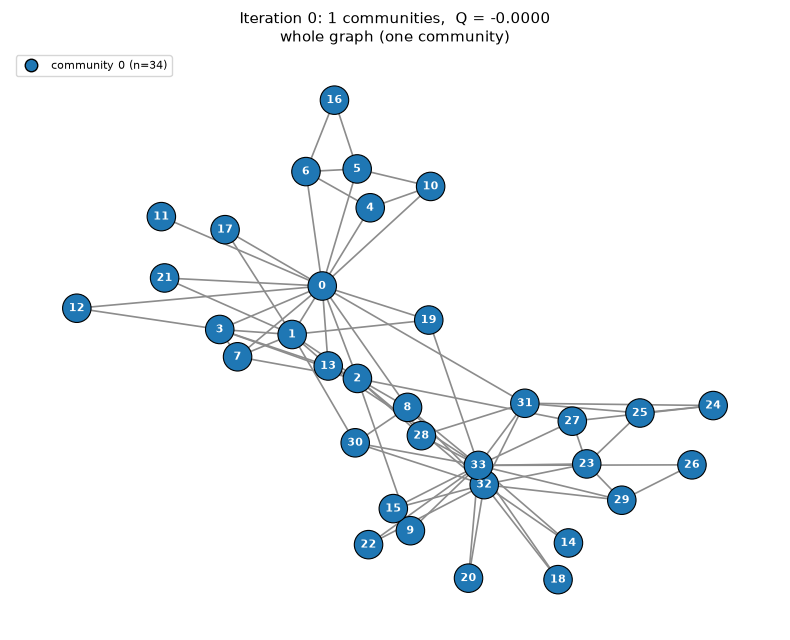

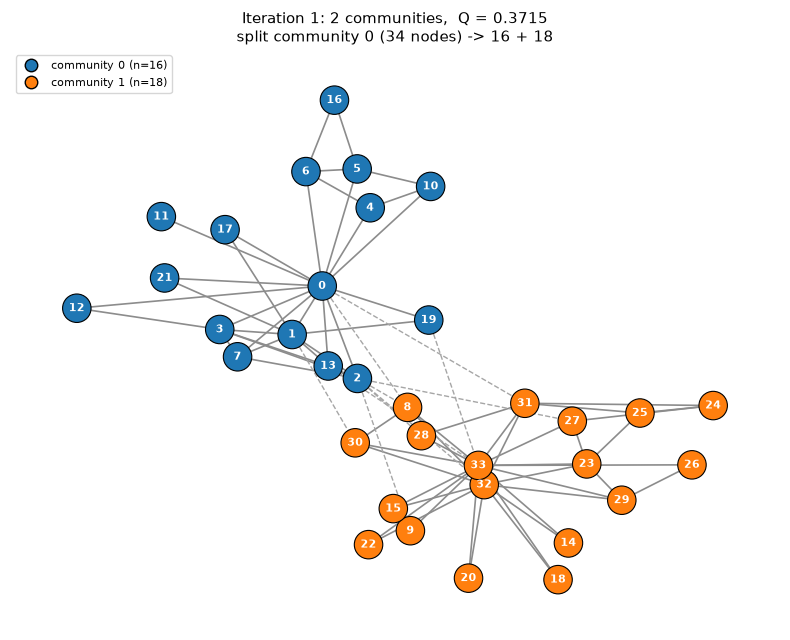

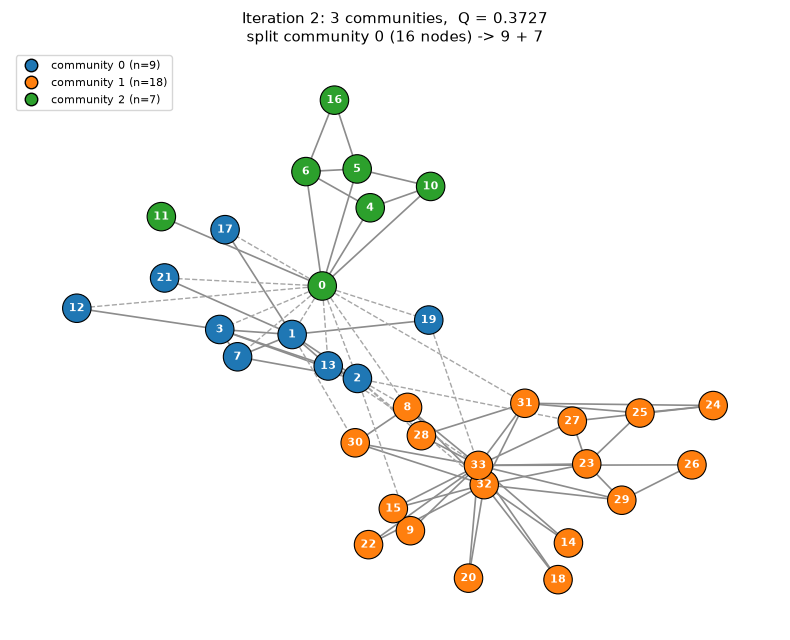

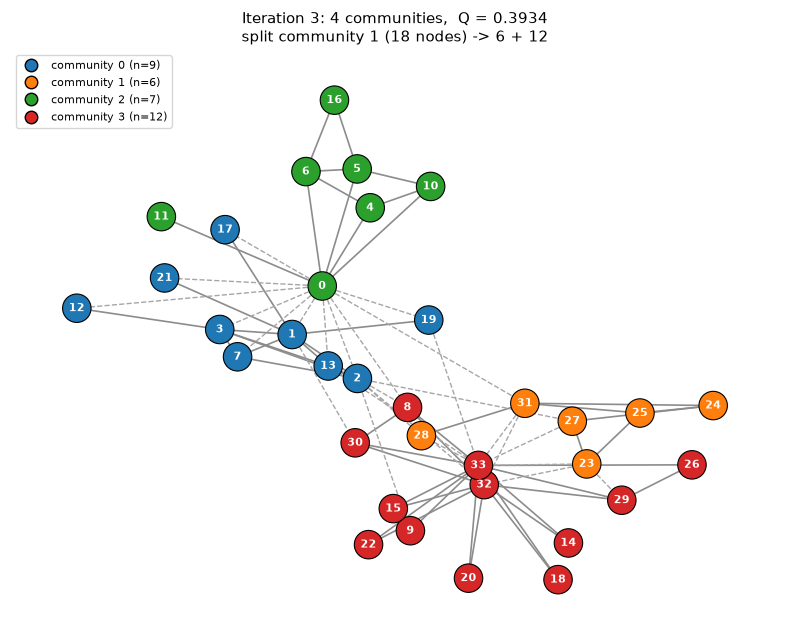

In [7]:
pos = nx.spring_layout(G, seed=42)               # computed ONCE and reused
cmap = plt.get_cmap("tab10")
color_of = lambda cid: cmap(cid % 10)

def draw_snapshot(h):
    fig, ax = plt.subplots(figsize=(8, 6.5))
    lab = h["label"]
    inside  = [(u, v) for u, v in G.edges() if lab[u] == lab[v]]
    between = [(u, v) for u, v in G.edges() if lab[u] != lab[v]]
    nx.draw_networkx_edges(G, pos, edgelist=inside,  edge_color="0.55", width=1.2, ax=ax)
    nx.draw_networkx_edges(G, pos, edgelist=between, edge_color="0.65", width=1.0, style="dashed", ax=ax)
    nx.draw_networkx_nodes(G, pos, nodelist=nodes, node_color=[color_of(lab[i]) for i in nodes],
                           node_size=420, edgecolors="black", linewidths=0.8, ax=ax)
    nx.draw_networkx_labels(G, pos, font_size=8, font_color="white", font_weight="bold", ax=ax)
    handles = [plt.Line2D([], [], marker="o", ls="", markersize=9, markerfacecolor=color_of(cid),
                          markeredgecolor="black", label=f"community {cid} (n={len(C)})")
               for cid, C in sorted(h["parts"].items())]
    ax.legend(handles=handles, loc="upper left", fontsize=8, frameon=True)
    ax.set_title(f"Iteration {h['iter']}: {len(h['parts'])} communities,  Q = {h['Q']:.4f}\n{h['event']}", fontsize=11)
    ax.axis("off")
    fig.tight_layout()
    fig.savefig(f"assets/partition_iter{h['iter']}.png", dpi=150)
    plt.show()

for h in history:
    draw_snapshot(h)

## 6. Node metrics after each split
For every iteration the four metrics are computed for all 34 nodes inside their community (iteration 0 = the full graph).
Below: the 5 highest-scoring nodes for every metric at every iteration, and the mean metric value over the graph.

In [8]:
n_iter = len(history)
M = {name: np.vstack([h["metrics"][name] for h in history]) for name in METRICS}   # shape (n_iter, n)

def top_set(values, r=5):
    # Indices of the r largest values, including every node tied with the r-th value.
    thr = np.sort(values)[::-1][r - 1]
    return [int(i) for i in np.where(values >= thr - 1e-12)[0]]

for name in METRICS:
    print(f"== {name} ==")
    for t in range(n_iter):
        v = M[name][t]
        order = [int(i) for i in np.argsort(-v, kind="stable")[:5]]
        ties = len(top_set(v)) - 5
        note = f"   [+{ties} more tied at the cut-off]" if ties > 0 else ""
        print(f"  iter {t}: mean = {v.mean():.4f} | top 5: " + ", ".join(f"{i} ({v[i]:.3f})" for i in order) + note)

print("\nNodes in the top 5 (ties included) at EVERY iteration:")
for name in METRICS:
    common = set.intersection(*[set(top_set(M[name][t])) for t in range(n_iter)])
    print(f"  {name:12s}: {sorted(common)}")

== degree ==
  iter 0: mean = 0.1390 | top 5: 33 (0.515), 0 (0.485), 32 (0.364), 2 (0.303), 1 (0.273)
  iter 1: mean = 0.2505 | top 5: 0 (0.933), 33 (0.882), 32 (0.647), 1 (0.533), 3 (0.400)
  iter 2: mean = 0.3245 | top 5: 33 (0.882), 1 (0.875), 0 (0.833), 5 (0.667), 6 (0.667)
  iter 3: mean = 0.3981 | top 5: 33 (1.000), 1 (0.875), 0 (0.833), 32 (0.818), 5 (0.667)   [+1 more tied at the cut-off]
== betweenness ==
  iter 0: mean = 0.0440 | top 5: 0 (0.438), 33 (0.304), 32 (0.145), 2 (0.144), 31 (0.138)
  iter 1: mean = 0.0568 | top 5: 0 (0.690), 33 (0.570), 32 (0.201), 31 (0.113), 1 (0.074)
  iter 2: mean = 0.0785 | top 5: 1 (0.655), 33 (0.570), 0 (0.378), 3 (0.262), 32 (0.201)
  iter 3: mean = 0.1024 | top 5: 1 (0.655), 33 (0.564), 31 (0.400), 0 (0.378), 3 (0.262)
== closeness ==
  iter 0: mean = 0.4265 | top 5: 0 (0.569), 2 (0.559), 33 (0.550), 31 (0.541), 8 (0.516)   [+2 more tied at the cut-off]
  iter 1: mean = 0.5558 | top 5: 0 (0.938), 33 (0.895), 32 (0.739), 1 (0.652), 3 (0.600

### Evolution of every metric
For each metric: **left**, one line per node across iterations (the 5 nodes with the highest average value are coloured and labelled, all others are thin grey lines); **right**, a node × iteration heat-map showing all 34 nodes.

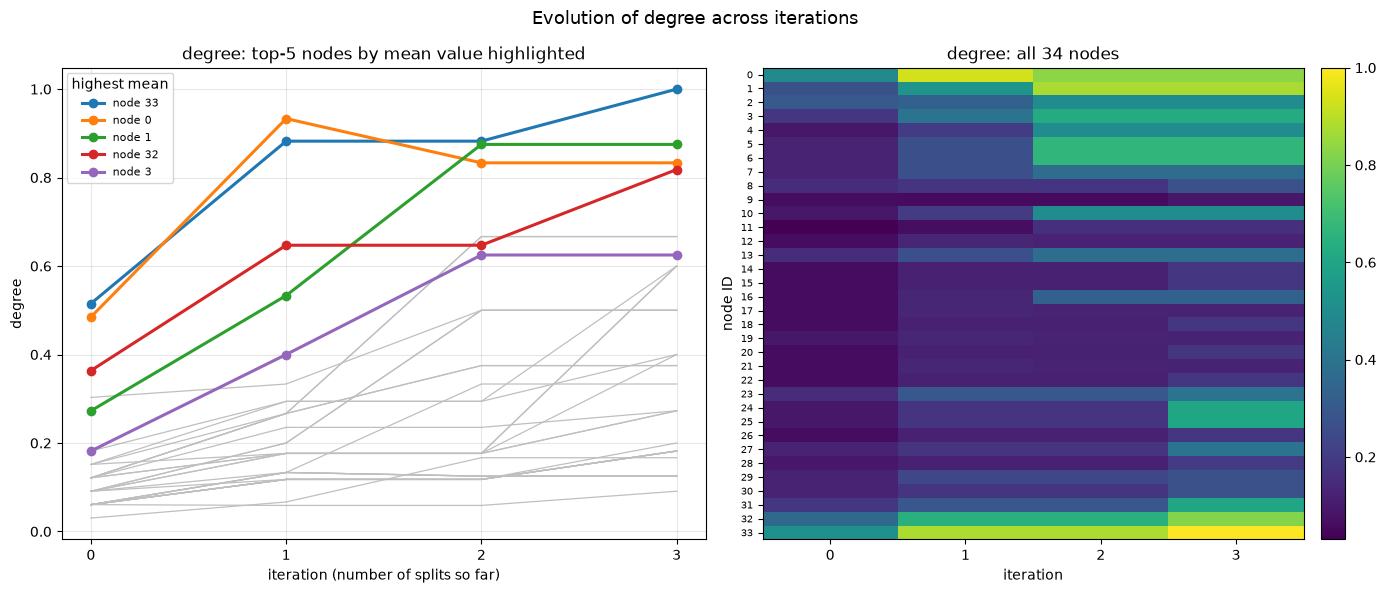

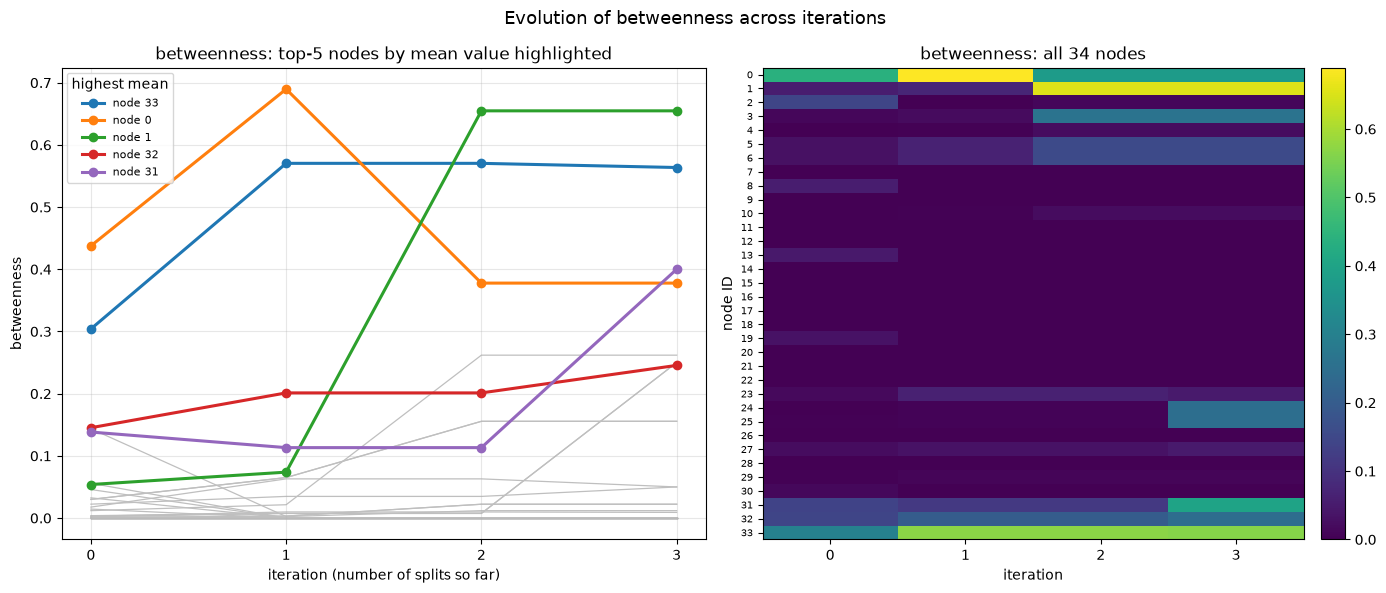

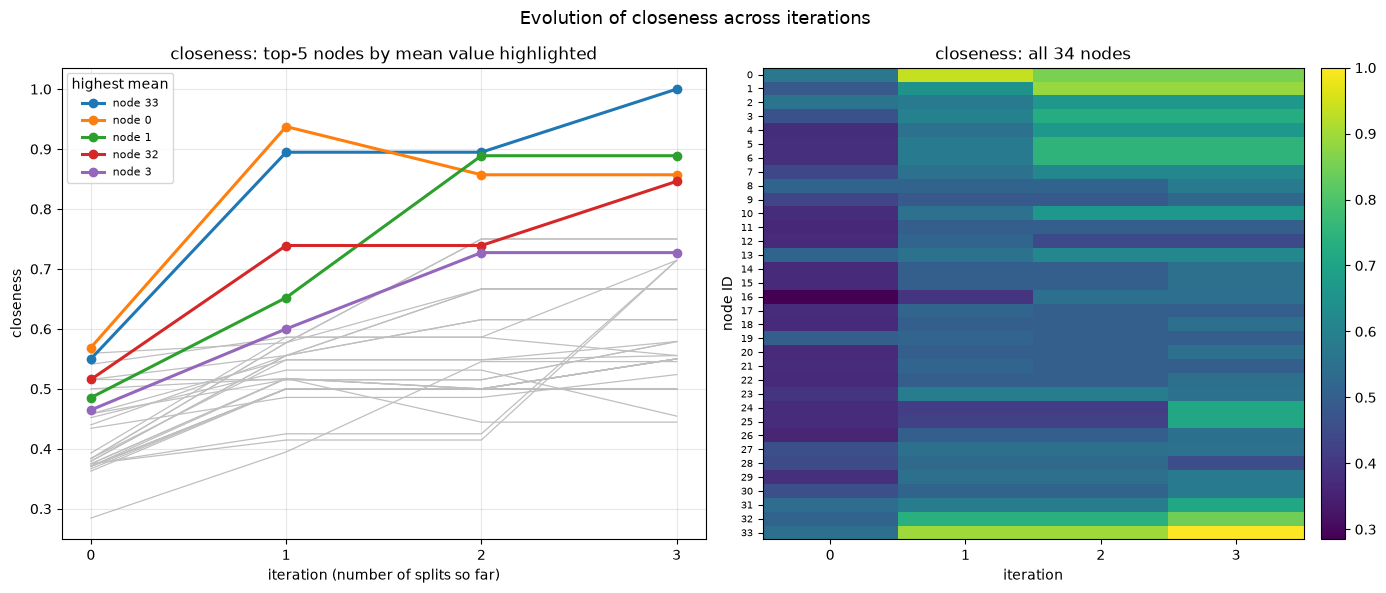

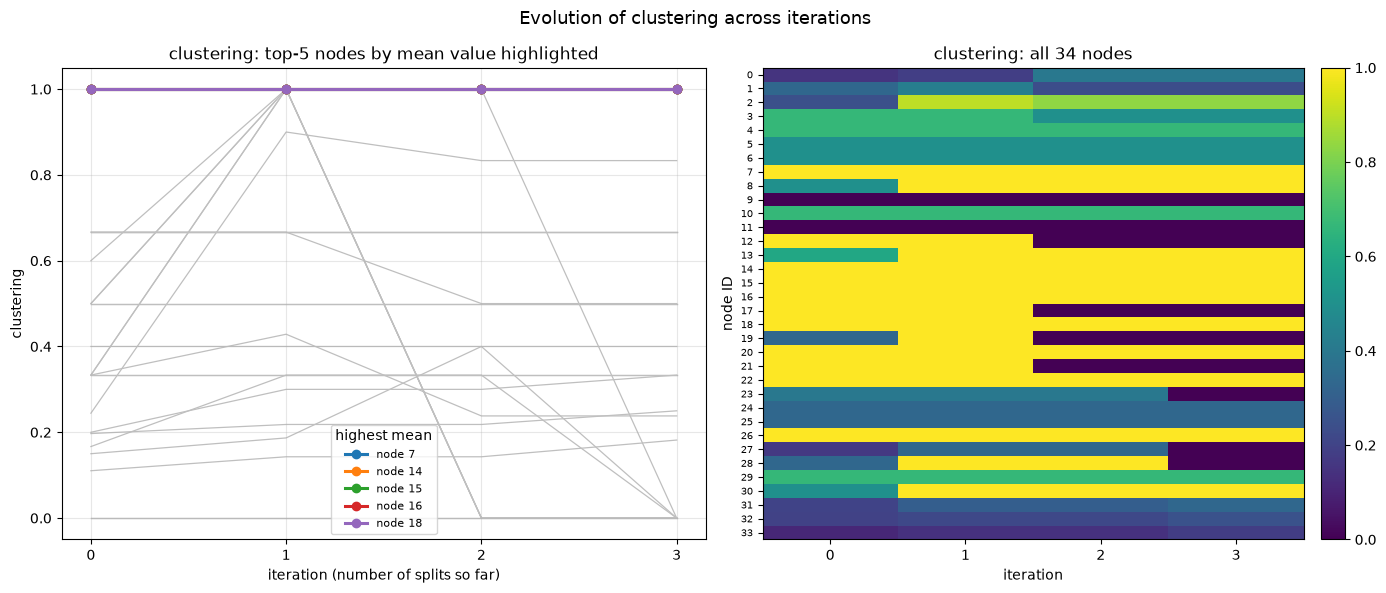

In [9]:
def plot_evolution(name):
    data = M[name]                                        # (n_iter, n)
    top = np.argsort(-data.mean(axis=0), kind="stable")[:5]
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1.1, 1]})
    x = np.arange(n_iter)
    for i in nodes:
        if i not in top:
            ax1.plot(x, data[:, i], color="0.75", lw=0.9, zorder=1)
    for j, i in enumerate(top):
        ax1.plot(x, data[:, i], marker="o", lw=2.2, color=cmap(j), label=f"node {i}", zorder=3)
    ax1.set_xticks(x)
    ax1.set_xlabel("iteration (number of splits so far)")
    ax1.set_ylabel(name)
    ax1.set_title(f"{name}: top-5 nodes by mean value highlighted")
    ax1.legend(title="highest mean", fontsize=8, loc="best")
    ax1.grid(alpha=0.3)

    im = ax2.imshow(data.T, aspect="auto", cmap="viridis")
    ax2.set_xticks(x); ax2.set_yticks(nodes)
    ax2.set_yticklabels(nodes, fontsize=7)
    ax2.set_xlabel("iteration"); ax2.set_ylabel("node ID")
    ax2.set_title(f"{name}: all 34 nodes")
    fig.colorbar(im, ax=ax2, fraction=0.046, pad=0.03)
    fig.suptitle(f"Evolution of {name} across iterations", fontsize=13)
    fig.tight_layout()
    fig.savefig(f"assets/evolution_{name}.png", dpi=150)
    plt.show()

for name in METRICS:
    plot_evolution(name)

## 7. Discussion

**Partition quality.** The first split (Q = 0.372) recovers the real fission of the club for 33 of 34 members; only node 8 is placed on the wrong side, the well-known misclassification for this method (Newman, 2006). Two further splits raise Q to 0.373 and then 0.393, and the recursion stops with **four communities**: {0,4,5,6,10,11,16}, {1,2,3,7,12,13,17,19,21}, {8,9,14,15,18,20,22,26,29,30,32,33} and {23,24,25,27,28,31}. This is the four-community result usually quoted for Newman's leading-eigenvector method (Q ≈ 0.393). The second split is marginal (ΔQ ≈ 0.001), the third is the one that adds real structure (ΔQ ≈ 0.021).

*Why is Newman's diagonal correction necessary?* It used the plain block of $B$ as $B^{(C)}$. Newman's generalised matrix subtracts the row sums on the diagonal, $B^{(C)}_{ij}=B_{ij}-\delta_{ij}\sum_{l\in C}B_{il}$; only then does $\tfrac{1}{4m}s^\top B^{(C)}s$ equal the true change in $Q$ caused by splitting $C$. With the plain block the $\lambda_1>0$ test is far too permissive for small blocks (e.g. $\lambda_1\approx 2.1$ for a 6-node block versus ≈0 here), so it kept splitting and even peeled off the degree-1 node 11. Note that the over-split five-community partition happens to have a *higher* Q (0.409) than the four-community one: Newman's recursive method is greedy and has no refinement step, so it does not maximise Q globally; it returns the partition produced by its stopping rule.

**Which nodes stay central.** Nodes **0 and 33** (the instructor "Mr. Hi" and the administrator/president) are the most robust hubs: they are in the top 5 for degree, betweenness and closeness at *every* iteration, and node **1** is also in the degree top 5 throughout. Clustering behaves differently: it is dominated by peripheral nodes inside tight groups (7, 14, 15, 16, 18, 20, 22, 26 keep clustering 1.0 at all iterations), i.e. the *least* central nodes are the most clustered.

**How community structure shapes the metrics.**
- *Degree and closeness rise as communities shrink* (mean degree 0.139 → 0.398, mean closeness 0.427 → 0.627). Part of this is mechanical: within a community, degree is divided by $n_C-1$ and distances are shorter. Absolute values are therefore not comparable across iterations; ranks are.
- *Betweenness exposes local brokers.* Node 0 jumps from 0.438 to 0.690 when it becomes the centre of a 16-node community (iteration 1), then falls to 0.378 once the community splits. Node 1 goes from near-zero globally to the top betweenness (0.655) at iterations 2–3, when it becomes the connector of its 9-node community, and node 31 rises to 0.400 inside {23,24,25,27,28,31}. A node's brokerage depends on which community it is measured in.
- *Clustering* is local: its mean rises from 0.571 to 0.684 after the first split (cross-community edges removed) but then falls to 0.560 and 0.512, because the later splits cut through triangles.

**Caveat.** Metrics here are computed on community-induced subgraphs, as stated in the conventions; they describe a node's role *within its group*. The iteration-0 values are the full-graph metrics, which is why hubs 0 and 33 dominate there. Communities produced by the sign rule may also be disconnected inside, in which case NetworkX's closeness uses its default (Wasserman–Faust) scaling.


## 8. References
- M. E. J. Newman (2006). *Modularity and community structure in networks.* Proceedings of the National Academy of Sciences **103**(23): 8577–8582.
- W. W. Zachary (1977). *An information flow model for conflict and fission in small groups.* Journal of Anthropological Research **33**(4): 452–473.
- Course handout, *Modularity on the Karate Club Graph*, DSC212: Graph Theory Module.
- NetworkX documentation: `degree_centrality`, `betweenness_centrality`, `closeness_centrality`, `clustering`, `karate_club_graph`.